# Week 3 — Food Delivery Visualization & Interpretation

Kagnus Project 3. Five finalized visualizations from the **same Week 1 cleaned dataset**. All figures are generated from calculated values and saved to `visualizations/`. Run from repository root (or `notebooks/`); do not overwrite earlier notebooks. Associations are not causal effects.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid", context="notebook")
DATA = Path("data/processed/cleaned_food_delivery.csv")
if not DATA.exists(): DATA = Path("../data/processed/cleaned_food_delivery.csv")
assert DATA.exists(), "Cleaned Week 1 CSV not found"
OUT = Path("visualizations") if Path("data/processed/cleaned_food_delivery.csv").exists() else Path("../visualizations")
OUT.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(DATA)
df["duration_min"] = pd.to_numeric(df["Time_taken (min)"], errors="coerce")
valid = df.loc[df.duration_min.notna() & df.duration_min.ge(0)].copy()
for col in ["Road_traffic_density", "Weather_conditions", "Type_of_vehicle"]:
    valid[col] = valid[col].astype("string").str.strip().fillna("Missing").replace("", "Missing")
print(f"Valid duration records: {len(valid):,} / {len(df):,}")
print("Data source:", DATA)


Valid duration records: 45,584 / 45,584
Data source: data/processed/cleaned_food_delivery.csv


## 1. Delivery duration distribution — histogram

**Why:** A histogram shows the typical delivery-time range, shape and possible extremes. The x-axis is in minutes; the y-axis counts deliveries.

,metric,value
0,count,45584.000
1,mean_min,26.294
2,median_min,26.000
3,q1_min,19.000
4,q3_min,32.000
5,min_min,10.000
6,max_min,54.000
7,skewness,0.486


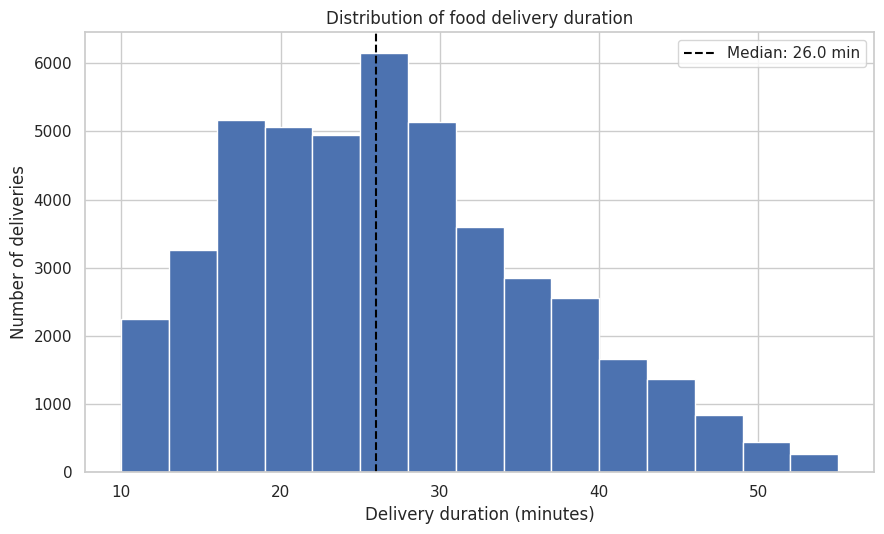

In [2]:
s = valid["duration_min"]
display(pd.DataFrame({"metric":["count", "mean_min", "median_min", "q1_min", "q3_min", "min_min", "max_min", "skewness"], "value":[s.count(),s.mean(),s.median(),s.quantile(.25),s.quantile(.75),s.min(),s.max(),s.skew()]}).round(3))
fig, ax = plt.subplots(figsize=(9,5.5))
ax.hist(s, bins=np.arange(np.floor(s.min()),np.ceil(s.max())+3,3), edgecolor="white")
ax.axvline(s.median(),color="black",ls="--",lw=1.5,label=f"Median: {s.median():.1f} min")
ax.set(title="Distribution of food delivery duration",xlabel="Delivery duration (minutes)",ylabel="Number of deliveries")
ax.legend(); fig.tight_layout(); fig.savefig(OUT/"01_delivery_duration_distribution.png",dpi=170,bbox_inches="tight");plt.show()


**Interpretation:** Across 45,584 valid deliveries, the mean is 26.29 minutes and the median is 26 minutes; the middle 50% lies between 19 and 32 minutes. The histogram illustrates concentration near the central range and the observed extremes of 10–54 minutes; these are not necessarily data errors. **Limitation:** Duration alone cannot explain why an individual delivery was fast or slow, and rounding/bins affect the visual appearance.

## 2. Traffic comparison — median bar chart

**Why:** Medians compare typical delivery duration across traffic groups while reducing sensitivity to long-duration values. Counts are shown to make sample-size differences visible.

,median_minutes,delivery_count
Road_traffic_density,,
Jam,31.0,14139
High,27.0,4423
Medium,27.0,10945
Missing,26.0,601
Low,20.0,15476


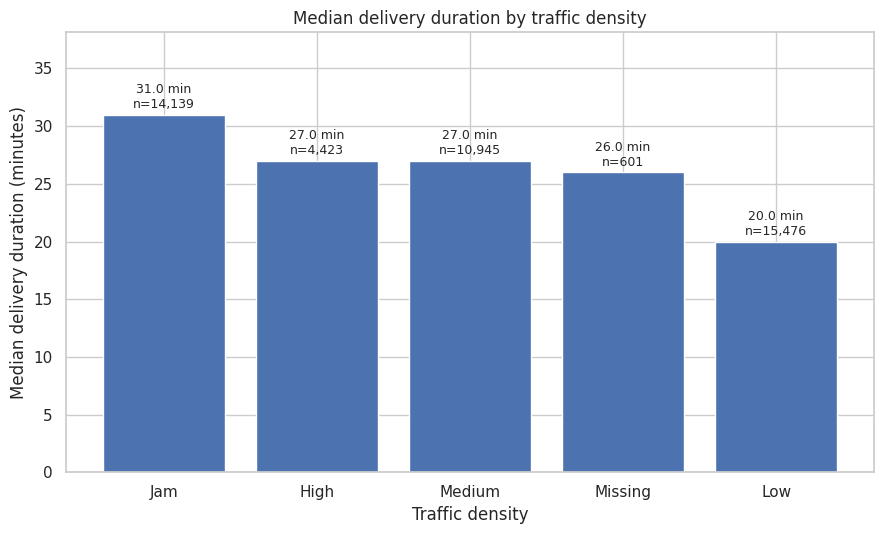

In [3]:
traffic = valid.groupby("Road_traffic_density",dropna=False)["duration_min"].agg(median_minutes="median", delivery_count="count").sort_values("median_minutes",ascending=False)
display(traffic)
fig,ax=plt.subplots(figsize=(9,5.5))
bars=ax.bar(traffic.index.astype(str),traffic.median_minutes)
for bar,med,n in zip(bars,traffic.median_minutes,traffic.delivery_count):
    ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+.3,f"{med:.1f} min\nn={n:,}",ha="center",va="bottom",fontsize=9)
ax.set_ylim(0,max(traffic.median_minutes)*1.23)
ax.set(title="Median delivery duration by traffic density",xlabel="Traffic density",ylabel="Median delivery duration (minutes)")
fig.tight_layout();fig.savefig(OUT/"02_traffic_comparison.png",dpi=170,bbox_inches="tight");plt.show()


**Interpretation:** The highest observed median is **Jam** at **31.0 minutes** (n=14,139), versus **Low** at **20.0 minutes** (n=15,476). This difference is an association and may also reflect city, distance, time of day or delivery mix. **Limitation:** Traffic categories are observational and do not establish that traffic caused the difference.

## 3. Weather comparison — mean bar chart

**Why:** Mean duration compares average delivery time across weather groups; group sizes and means are calculated directly from valid rows.

,mean_minutes,delivery_count
Weather_conditions,,
Cloudy,28.92,7533
Fog,28.91,7653
Missing,26.55,616
Windy,26.12,7422
Sandstorms,25.88,7494
Stormy,25.87,7584
Sunny,21.86,7282


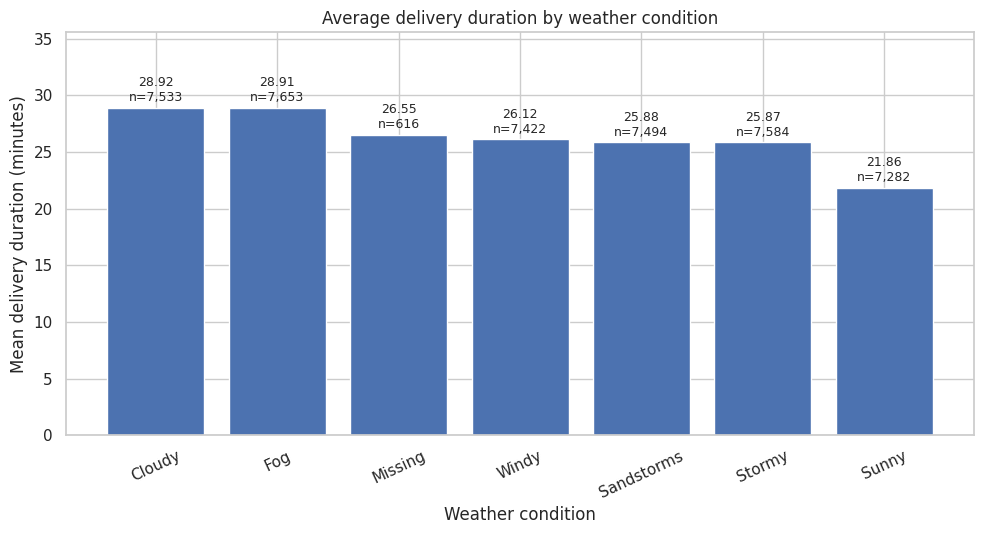

In [4]:
weather=valid.groupby("Weather_conditions",dropna=False)["duration_min"].agg(mean_minutes="mean",delivery_count="count").sort_values("mean_minutes",ascending=False)
display(weather.round(2))
fig,ax=plt.subplots(figsize=(10,5.5))
bars=ax.bar(weather.index.astype(str),weather.mean_minutes)
for bar,avg,n in zip(bars,weather.mean_minutes,weather.delivery_count):
    ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+.3,f"{avg:.2f}\nn={n:,}",ha="center",va="bottom",fontsize=9)
ax.set_ylim(0,max(weather.mean_minutes)*1.23)
ax.set(title="Average delivery duration by weather condition",xlabel="Weather condition",ylabel="Mean delivery duration (minutes)")
ax.tick_params(axis="x",rotation=25)
fig.tight_layout();fig.savefig(OUT/"03_weather_comparison.png",dpi=170,bbox_inches="tight");plt.show()


**Interpretation:** **Cloudy** has the highest observed mean (**28.92 minutes**, n=7,533), while **Sunny** has the lowest (**21.86 minutes**, n=7,282). The comparison suggests weather categories are associated with different average delivery times. **Limitation:** The averages do not control for traffic, distance, city, or other factors, so they cannot establish weather as the cause.

## 4. Distance versus duration — scatter plot

**Why:** Compare approximate straight-line distance (haversine kilometres) with duration (minutes), calculate Pearson correlation, and identify unusual coordinates. This is not road-route distance.

Valid coordinate pairs: 41,944; Pearson r=-0.0029; distances >100 km: 431


,distance_km,duration_min
count,41944.000,41944.000
mean,107.081,26.311
std,1146.241,9.381
min,1.465,10.000
25%,4.658,19.000
50%,9.220,26.000
75%,13.761,32.000
max,19692.675,54.000


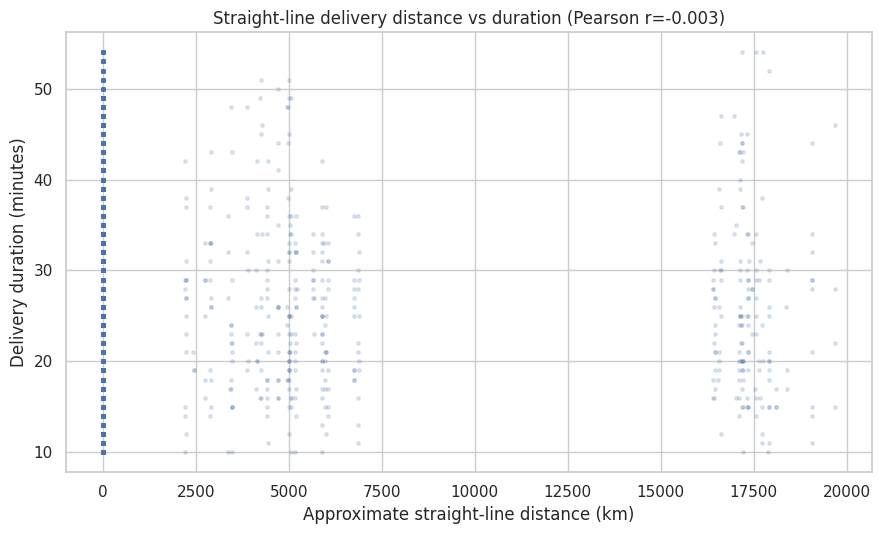

In [5]:
coords=["Restaurant_latitude","Restaurant_longitude","Delivery_location_latitude","Delivery_location_longitude"]
a=valid[coords].apply(pd.to_numeric,errors="coerce")
coord_ok=a.notna().all(axis=1)
for col in ["Restaurant_latitude","Delivery_location_latitude"]:coord_ok &= a[col].between(-90,90) & a[col].ne(0)
for col in ["Restaurant_longitude","Delivery_location_longitude"]:coord_ok &= a[col].between(-180,180) & a[col].ne(0)
p=a.loc[coord_ok]
lat1=np.radians(p.Restaurant_latitude);lat2=np.radians(p.Delivery_location_latitude)
dlat=lat2-lat1;dlon=np.radians(p.Delivery_location_longitude-p.Restaurant_longitude)
h=np.sin(dlat/2)**2+np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
distance_km=6371.0*2*np.arcsin(np.sqrt(np.clip(h,0,1)))
pairs=pd.DataFrame({"distance_km":distance_km,"duration_min":valid.loc[coord_ok,"duration_min"]}).dropna()
r=pairs.distance_km.corr(pairs.duration_min)
print(f"Valid coordinate pairs: {len(pairs):,}; Pearson r={r:.4f}; distances >100 km: {(pairs.distance_km>100).sum():,}")
display(pairs.describe().round(3))
fig,ax=plt.subplots(figsize=(9,5.5))
ax.scatter(pairs.distance_km,pairs.duration_min,s=6,alpha=.17,rasterized=True)
ax.set(title=f"Straight-line delivery distance vs duration (Pearson r={r:.3f})",xlabel="Approximate straight-line distance (km)",ylabel="Delivery duration (minutes)")
fig.tight_layout();fig.savefig(OUT/"04_distance_vs_duration.png",dpi=170,bbox_inches="tight");plt.show()


**Interpretation:** The calculated Pearson correlation is **-0.0029** across **41,944** valid coordinate pairs, indicating essentially no overall linear relationship in these recorded coordinates. Some computed distances exceed 100 km (431 cases), which warrants caution about coordinate quality and may visually compress the main cluster. **Limitation:** Haversine distance is not actual driving distance, and extreme or anomalous coordinates can distort the plot and correlation.

## 5. Vehicle comparison — box plot

**Why:** Box plots display each vehicle group’s median, interquartile range (IQR), whiskers, and plotted outliers. Unlike a bar chart, they show spread and variability.

,count,median,q1,q3,iqr
Type_of_vehicle,,,,,
bicycle,68,26.0,19.0,32.25,13.25
motorcycle,26429,26.0,20.0,34.00,14.00
electric_scooter,3814,24.0,17.0,30.00,13.00
scooter,15273,24.0,17.0,30.00,13.00


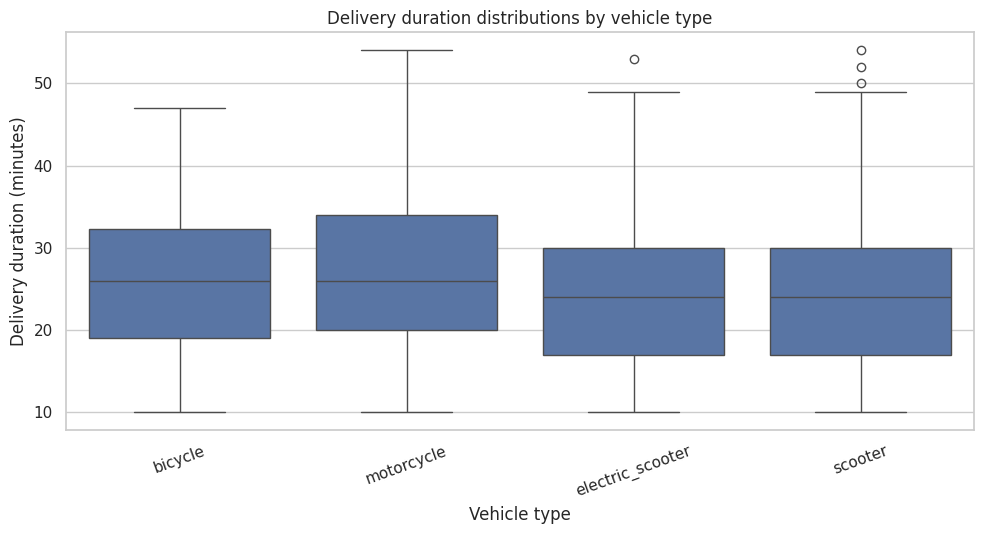

In [6]:
vehicle=valid.groupby("Type_of_vehicle",dropna=False)["duration_min"].agg(count="count",median="median",q1=lambda x:x.quantile(.25),q3=lambda x:x.quantile(.75)).sort_values("median",ascending=False)
vehicle["iqr"]=vehicle.q3-vehicle.q1
display(vehicle)
order=vehicle.index.astype(str).tolist()
fig,ax=plt.subplots(figsize=(10,5.5))
sns.boxplot(data=valid,x="Type_of_vehicle",y="duration_min",order=order,showfliers=True,ax=ax)
ax.set(title="Delivery duration distributions by vehicle type",xlabel="Vehicle type",ylabel="Delivery duration (minutes)")
ax.tick_params(axis="x",rotation=20)
fig.tight_layout();fig.savefig(OUT/"05_vehicle_comparison.png",dpi=170,bbox_inches="tight");plt.show()


**Interpretation:** Vehicle medians range from **24.0 to 26.0 minutes**; the boxes show the middle 50% and whiskers/outlier markers show variation beyond the quartiles. Differences in median and IQR may reflect different operating contexts or delivery assignments rather than vehicle performance alone. **Limitation:** Vehicle categories have unequal sample sizes and are not controlled for distance, city, or traffic.

## Export verification and reproducibility

All five exported PNG files must exist, have nonzero size, and match the notebook figures. Earlier notebooks and charts are intentionally left unchanged.

In [7]:
expected=["01_delivery_duration_distribution.png","02_traffic_comparison.png","03_weather_comparison.png","04_distance_vs_duration.png","05_vehicle_comparison.png"]
for name in expected:
    path=OUT/name
    assert path.exists() and path.stat().st_size>0, f"Missing or empty: {path}"
    print(f"OK: {path} ({path.stat().st_size:,} bytes)")
print("Week 3 export verification PASSED")

OK: visualizations/01_delivery_duration_distribution.png (58,782 bytes)
OK: visualizations/02_traffic_comparison.png (65,115 bytes)
OK: visualizations/03_weather_comparison.png (95,211 bytes)
OK: visualizations/04_distance_vs_duration.png (100,119 bytes)
OK: visualizations/05_vehicle_comparison.png (69,618 bytes)
Week 3 export verification PASSED
